# Milestone 1: playing time after a transfer

**Note:** The two raw sources, Wyscout and Transfermarkt, use different player IDs, and turning
them into the transfer dataset turned out to be far more complex than we expected, as we needed to match each Wyscout player to
the right Transfermarkt player, build the 12-month playing-time label, and filter the transfers. We used Claude to help write the python scripts that turned the raw datasets into the processed files in data/
that this notebook reads. If you would like to see that code, we can to share it as well.


For this milestone, our goal is for each player joining a new club (transferred) predict his playing-time share in the next 12 months (player's minutes played / team's total minutes played), which is a number between 0 and 1 (0 = didn't play at all, 1 = played every minute). We joined Wyscout 2017/18 (the only season we could find) match events to the Transfermarkt which contains the transfers for many seasons. So in transfers.csv each row represents a transfer. The data files we submitted have been extracted from the Wyscout and Transfermrkt datasets, as written above, and we only submitted what is needed to make it simpler and easier to run and understand.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split, RepeatedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error, silhouette_score, adjusted_rand_score

DATA = Path("data")
data = pd.read_csv(DATA / "transfers.csv", parse_dates=["transfer_date"])
players = pd.read_csv(DATA / "player_features.csv")
funnel = pd.read_csv(DATA / "funnel.csv")
SEED = 42

## 1 · The data

In [2]:
data[["player_name", "from_club_name", "to_club_name", "transfer_date", "position",
      "age", "log_mv", "prev_share_tm", "wy_share", "y"]].head()

,player_name,from_club_name,to_club_name,transfer_date,position,age,log_mv,prev_share_tm,wy_share,y
0,Leonardo Spinazzola,Atalanta,Juventus,2018-06-30,Defender,25.264887,16.300417,0.440643,0.440058,0.174854
1,Saidy Janko,Saint-Étienne,Porto,2018-07-01,Defender,22.691307,14.914123,0.414912,0.415205,0.000000
2,Luca Waldschmidt,Hamburg,Freiburg,2018-07-01,Attack,22.116359,14.731802,0.257843,0.256536,0.561111
3,Thomas Lemar,Monaco,Atlético,2018-07-01,Midfield,22.633812,17.989898,0.696784,0.696491,0.534211
4,Pepe Reina,SSC Napoli,AC Milan,2018-07-01,Goalkeeper,35.832991,13.815512,0.973684,0.973684,0.095906


In [3]:
print(funnel.to_string(index=False))
n_players, n_linked = funnel.n.iloc[0], funnel.n.iloc[1]
print(f"\nmatched {n_linked} of {n_players} Wyscout players to Transfermarkt ({n_linked / n_players:.1%})")

                                                 step     n
          Wyscout players with 2017/18 league minutes  2561
                     linked to a Transfermarkt player  2523
              transfers of linked players (all years) 14822
                       dated 2018-05-15 to 2019-02-15   795
                                   club-to-club moves   791
                               excluding loan returns   522
                                first move per player   464
  not a loan pass-through (left again within 60 days)   451
               destination club covered (>= 10 games)   349
                    >= 450 Wyscout minutes  ->  FINAL   267

matched 2523 of 2561 Wyscout players to Transfermarkt (98.5%)


count    267.000
mean       0.506
std        0.281
min        0.000
25%        0.271
50%        0.553
75%        0.735
max        1.000
Name: y, dtype: float64
never played: 0.022   played every minute: 0.015


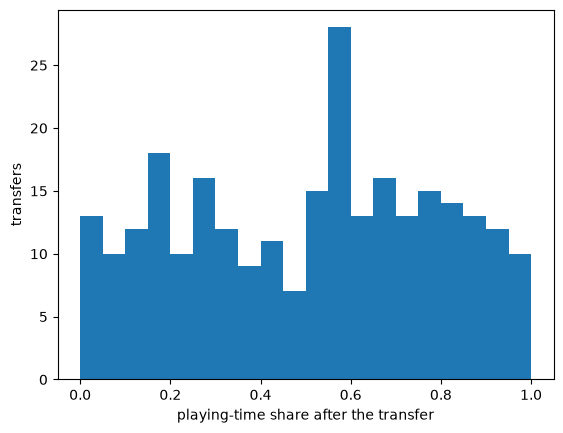

In [4]:
print(data.y.describe().round(3))
print("never played:", round((data.y == 0).mean(), 3), "  played every minute:", round((data.y == 1).mean(), 3))

plt.hist(data.y, bins=20)
plt.xlabel("playing-time share after the transfer")
plt.ylabel("transfers")
plt.show()

In [5]:
print("players:", data.player_id.nunique())
print("destination clubs:", data.to_club_id.nunique())
print("selling clubs:", data.from_club_id.nunique())

players: 267
destination clubs: 110
selling clubs: 98


We started with 2523 Wyscout players linked to a Transfermarkt player, in that year there were 795 transfers between those players, 791 were from club to club, 522 weren't loan returns, 349 were the first move of the player in the window, were the destination club played at least 10 games on the new club, and out of those only 267 played at least 450 minutes before the transfer. So, from the 2523 initial players, we only ended up with 267 rows (transfers) that we can label and use as data for our model. In this project, the label is a number, not a class, so the label balance is its distribution, and here we will focus on the mean of share-time played by all the players, which is aproximately 0.51. We could also group the teams represented in those transfers as destination clubs or selling clubs. 

## 2 · The split

In [6]:
train, test = train_test_split(data, test_size=0.2, random_state=SEED)
print("same as our saved split:", (test.split == "test").all() and (train.split == "train").all())

print("train", len(train), "  test", len(test))
print("mean y in train", round(train.y.mean(), 3), "  in test", round(test.y.mean(), 3))
print("players on both sides:", len(set(train.player_id) & set(test.player_id)), " <- must be 0")
print("destination clubs on both sides:", len(set(train.to_club_id) & set(test.to_club_id)))

same as our saved split: True
train 213   test 54
mean y in train 0.509   in test 0.495
players on both sides: 0  <- must be 0
destination clubs on both sides: 32


We split our data by the player, so no player can be in both the training and testing set. Destination clubs can repeat across train and test sets, but for now our features don't include the club, so the model won't overfit because of repeating clubs. However, a worry of ours was that repeating clubs might slightly affect the result, as players who transfer for the same club can compete for minutes in the matches. Later on we will use datasets containing multiple seasons (new FIFA dataset), so players will appear more than once, and to solve this problem we will split the dataset by player and time.

### What a leaky feature does

In [7]:
NUM = ["age", "log_mv", "prev_share_tm", "wy_share", "pass_acc"] + [c for c in data.columns if c.endswith("_p90")]
CAT = ["position"]

def linreg(num):
    prep = make_column_transformer(
        (make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()), num),
        (OneHotEncoder(handle_unknown="ignore"), CAT))
    return make_pipeline(prep, LinearRegression())

# the mistake: market value ONE YEAR AFTER the transfer instead of at the transfer
later = pd.read_csv(DATA / "market_value_one_year_later.csv")
data = data.merge(later, on="player_id", how="left")
train, test = data.loc[train.index], data.loc[test.index]

leaky = [c if c != "log_mv" else "log_mv_1y_after" for c in NUM]
for name, num in [("value at the transfer", NUM), ("value one year later (leak)", leaky)]:
    m = linreg(num).fit(train[num + CAT], train.y)
    print(f"{name:30s} test MSE {mean_squared_error(test.y, m.predict(test[num + CAT])):.4f}")
print(f"{'always predict the average':30s} test MSE {mean_squared_error(test.y, np.full(len(test), train.y.mean())):.4f}")

value at the transfer          test MSE 0.1041


value one year later (leak)    test MSE 0.0808
always predict the average     test MSE 0.0943


We decided to add this block to showcases a mistake we made in our first notebook, where we used the market value a year later as one of the features, which is a leak since a increase in market value tends to represent more minutes played, and a decrease less minutes played. After we noticed this mistake, we determined that every feature we use must come from before the transfer.

(Obviously here we puposefully reproduced our mistake to showcase it.)

## 3 · The model

In [8]:
model = linreg(NUM).fit(train[NUM + CAT], train.y)
n_params = model[-1].coef_.size + 1
print("linear regression, trainable parameters:", n_params, " for", len(train), "training rows")

linear regression, trainable parameters: 20  for 213 training rows


For this milestone we used the simplest model that could work, a linear regression on each player's features like age, market value, position, playing time before the move and the season stats per 90 minutes. Overall, we had 20 parameters for 213 training rows, which is a lot, specially for a simple linear regression model, we plan to change that in the future with more data.

## 4 · The error, and the baselines

For the error, we chose to report the MSE because a big error, like expecting a player to be a starter but then he barely plays, is much worse for a club than smaller errors, so mean squared error fits the problem.

In [9]:
mean_y = train.y.mean()
preds = {
    "always predict the average":  np.full(len(test), mean_y),
    "plays as much as last year":  test.prev_share_tm.fillna(mean_y).clip(0, 1),
    "linear regression":           model.predict(test[NUM + CAT]),
}
table = pd.DataFrame({
    "test MSE": {k: mean_squared_error(test.y, p) for k, p in preds.items()},
})

# cross-validation on the training rows, for the two models that need fitting
cv = RepeatedKFold(n_splits=5, n_repeats=10, random_state=SEED)
cv_lr = -cross_val_score(linreg(NUM), train[NUM + CAT], train.y, cv=cv, scoring="neg_mean_squared_error")
cv_mean = [mean_squared_error(train.y.iloc[va], np.full(len(va), train.y.iloc[tr].mean()))
           for tr, va in cv.split(train)]
table["CV MSE"] = pd.Series({"always predict the average": np.mean(cv_mean), "linear regression": cv_lr.mean()})
table.round(4)

,test MSE,CV MSE
always predict the average,0.0943,0.0756
plays as much as last year,0.1446,NaN
linear regression,0.1041,0.0799


Without cross-validation, the only score we would have is the test MSE. So, every time we compare models or features and keep the one with the best test score, we are tuning to those 54 transfers, so our choices will only be based on them, so the test score could be optimistic. Also, one score on 54 rows is very noisy, so we can't define if one model is really better than another. Cross-validation gives us a score from the training data averaged over many splits and with a standard deviation.

The MSE of predicting the average playing time was always lower than linear regression and the prediction that players will play as much as last year, which was the worst. This happens because we have a small dataset and many features that only describe the player, not the club it went to, and obviously the minutes played the year before not necessarily will be similar after moving to another team. So, the bar for next milestones is beating the model that always predicts the average, which has Cross Validation MSE of 0.0756. For the future, we plan on having data about the teams, and also more meaningful information about the players, which would help the model to beat the baseline.

## 5 · Optimisation checks

In [10]:
# twenty-row check: fit on 20 training rows spread across y, test on the same 20
twenty = train.sort_values("y").iloc[np.linspace(0, len(train) - 1, 20).astype(int)]
tiny = linreg(NUM).fit(twenty[NUM + CAT], twenty.y)
print("MSE on the same 20 rows:", round(mean_squared_error(twenty.y, tiny.predict(twenty[NUM + CAT])), 4),
      "  (variance of those 20:", round(twenty.y.var(ddof=0), 4), ")")

MSE on the same 20 rows: 0.0079   (variance of those 20: 0.0827 )


The error isn't exactly zero because there are parameters (position and intercept) that are dependent on each other, so not all columns are independent. So it leaves 18 independent parameters for 20 rows, and with fewer parameters than rows it's impossible to find a perfect fit. Still, the error is small, so the model works.

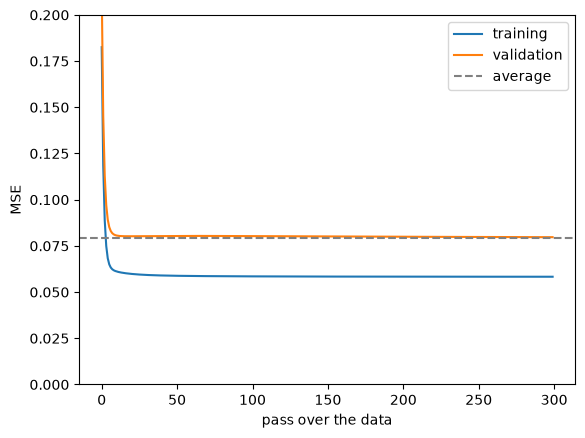

In [11]:
# training curve: the same linear model trained step by step with SGD
tr2, va = train_test_split(train, test_size=0.3, random_state=0)
prep = linreg(NUM)[0].fit(tr2[NUM + CAT])
X_tr, X_va = prep.transform(tr2[NUM + CAT]), prep.transform(va[NUM + CAT])

sgd = SGDRegressor(penalty=None, learning_rate="constant", eta0=0.002, random_state=0)
train_loss, val_loss = [], []
for step in range(300):
    sgd.partial_fit(X_tr, tr2.y)
    train_loss.append(mean_squared_error(tr2.y, sgd.predict(X_tr)))
    val_loss.append(mean_squared_error(va.y, sgd.predict(X_va)))

plt.plot(train_loss, label="training")
plt.plot(val_loss, label="validation")
plt.axhline(mean_squared_error(va.y, np.full(len(va), tr2.y.mean())), color="grey", ls="--", label="average")
plt.xlabel("pass over the data"); plt.ylabel("MSE"); plt.ylim(0, 0.2); plt.legend()
plt.show()

The training MSE goes down until about 0.06, and valdiation MSE decreases until about 0.08, never going below the average line, which means it doesn't learn anything better than the average.


## 6 · Player roles (our one clustering)

First, we grouped all players with at least 450 minutes played in 2017/18 by their position. Second, we clustered players of each position by playing style using 12 features, like stats per 90 minutes, and average position on the field. We tried to measure the style of the player, not the quality, so we left goals and assists left, since this can depend on luck, and also on the ability of the player, which doesn't particularly influence their playing stile.

In [12]:
FEATURES = ["passes_p90", "pass_acc", "progressive_passes_p90", "key_passes_p90", "crosses_p90",
            "shots_p90", "dribbles_p90", "duels_p90", "interceptions_p90",
            "avg_x", "avg_width", "final_third_share"]

pool = players[(players.wy_minutes >= 450) & players.wy_role.notna()].reset_index(drop=True)

def position_matrix(g):
    X = g[FEATURES].astype(float).copy()
    for f in FEATURES:
        if f.endswith("_p90"):
            X[f] = np.log1p(X[f])      # per-90 counts are skewed
    X = X.fillna(X.median())
    return ((X - X.mean()) / X.std(ddof=0)).to_numpy()   # z-score within the position

def kmeans(k, seed=SEED):
    return KMeans(n_clusters=k, n_init=20, random_state=seed)

print(pool.wy_role.value_counts())

wy_role
MD    706
DF    703
FW    403
GK    135
Name: count, dtype: int64


### Choosing k

In [13]:
# for each k: silhouette, and stability = how similar the clusters are when we refit on resampled players
# (adjusted Rand index, 1 = identical). Takes about 2 minutes.
def stability(X, k, n_boot=50):
    rng = np.random.default_rng(SEED)
    base = kmeans(k).fit_predict(X)
    scores = []
    for b in range(n_boot):
        idx = rng.integers(0, len(X), len(X))
        scores.append(adjusted_rand_score(base, kmeans(k, SEED + b + 1).fit(X[idx]).predict(X)))
    return np.mean(scores)

rows = []
for pos in ["DF", "MD", "FW"]:
    X = position_matrix(pool[pool.wy_role == pos].reset_index(drop=True))
    for k in range(2, 7):
        labels = kmeans(k).fit_predict(X)
        rows.append({"position": pos, "k": k, "silhouette": silhouette_score(X, labels), "stability": stability(X, k)})
pd.DataFrame(rows).pivot(index="k", columns="position", values=["silhouette", "stability"]).round(2)

silhouette             stability            
position         DF    FW    MD        DF    FW    MD
k                                                    
2              0.37  0.24  0.32      0.99  0.90  0.97
3              0.24  0.22  0.19      0.75  0.88  0.65
4              0.19  0.15  0.17      0.89  0.62  0.79
5              0.18  0.16  0.16      0.80  0.63  0.64
6              0.15  0.14  0.15      0.69  0.56  0.66

Silhouette and stability always favor k=2, but k=2 only splits players who play centrally from players who play wide, which doesn't tell us much about their roles. So we looked for the k above 2 where the clusters are still stable. For defenders and midfielders, the stability was higher at k=4, so we chose 4 clusters for each. For forwards, stability stays high up to k=3 and drops at k=4, so we choose 3.

In [14]:
K = {"DF": 4, "MD": 4, "FW": 3}
ANCHORS = {   # each role is named after a player in it, because k-means numbers clusters arbitrarily
    "DF": {7885: "Attacking full-back", 8653: "Defensive centre-back", 20459: "Ball-playing centre-back",
           8313: "Defensive full-back"},             # Bertrand, Maguire, Bonucci, Zabaleta
    "MD": {4488: "Ball-winning midfielder", 14812: "Wide midfielder", 3346: "Deep-lying midfielder",
           38021: "Attacking midfielder"},           # Saúl, Perišić, Busquets, De Bruyne
    "FW": {3359: "Creative forward", 5400: "Wide support forward", 8717: "Central striker"},  # Messi, G. Moreno, Kane
}

parts = []
for pos, g in pool.groupby("wy_role"):
    g = g.reset_index(drop=True)
    if pos == "GK":
        parts.append(g.assign(role="Goalkeeper"))
        continue
    labels = kmeans(K[pos]).fit_predict(position_matrix(g))
    names = {labels[g.index[g.wy_id == wid][0]]: name for wid, name in ANCHORS[pos].items()}
    parts.append(g.assign(role=[names[c] for c in labels]))
roles = pd.concat(parts)
roles.groupby(["wy_role", "role"]).size()

wy_role  role                    
DF       Attacking full-back         154
         Ball-playing centre-back    151
         Defensive centre-back       217
         Defensive full-back         181
FW       Central striker             195
         Creative forward            100
         Wide support forward        108
GK       Goalkeeper                  135
MD       Attacking midfielder        153
         Ball-winning midfielder     189
         Deep-lying midfielder       182
         Wide midfielder             182
dtype: int64

In [15]:
famous = ["Sergio Ramos", "Sergio Busquets", "N. Kanté", "K. De Bruyne", "L. Messi", "H. Kane"]
roles[roles.shortName.isin(famous)][["shortName", "wy_team", "role"]]

,shortName,wy_team,role
29,Sergio Ramos,Real Madrid,Ball-playing centre-back
19,L. Messi,Barcelona,Creative forward
74,H. Kane,Tottenham Hotspur,Central striker
24,Sergio Busquets,Barcelona,Deep-lying midfielder
391,N. Kanté,Chelsea,Deep-lying midfielder
400,K. De Bruyne,Manchester City,Attacking midfielder


The clusters naming we chose were: for defenders: Attacking full-back, Ball-playing centre-back, Defensive centre-back and Defensive full-back. For forwards: Central striker, Creative forward, and Wide support forward. For midfielders: Attacking midfielder, Ball-winning midfielder, Deep-lying midfielder, and Wide midfielder. We also check to see if famous players end up on the position we would expect them to be, this way we can check that the clustering made sense.

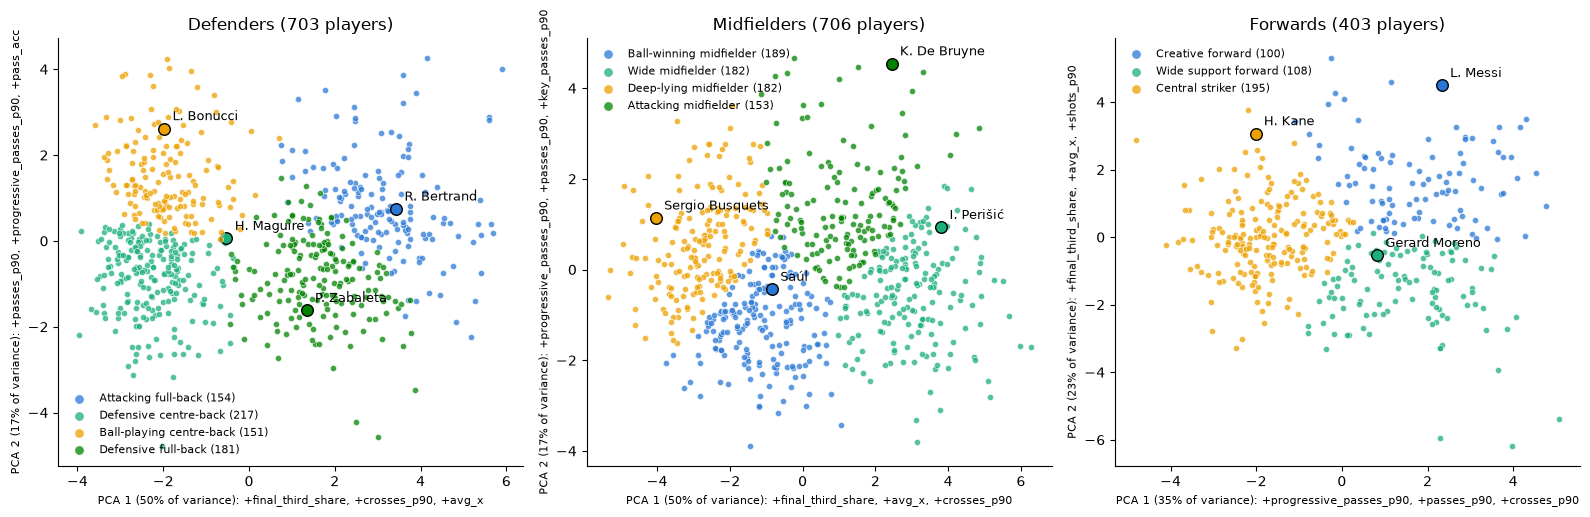

In [16]:
# what the roles look like: each position's 12 standardised features squeezed into 2 dimensions with PCA.
# PCA is only for the picture; k-means used all 12 features. Each axis lists the features that move it most.
COLOURS = ["#2a78d6", "#1baf7a", "#eda100", "#008300"]

fig, axes = plt.subplots(1, 3, figsize=(16, 5.2))
for ax, pos in zip(axes, ["DF", "MD", "FW"]):
    g = roles[roles.wy_role == pos].reset_index(drop=True)   # same players as the clustering
    X = position_matrix(g)
    pca = PCA(n_components=2).fit(X)
    xy = pca.transform(X)
    names = []
    for j in range(2):
        w = pca.components_[j]
        top = np.argsort(-np.abs(w))[:3]
        if w[top[0]] < 0:          # PCA's sign is arbitrary: flip so the top feature points right / up
            xy[:, j], w = -xy[:, j], -w
        names.append(f"PCA {j + 1} ({pca.explained_variance_ratio_[j]:.0%} of variance): "
                     + ", ".join(("+" if w[t] > 0 else "−") + FEATURES[t] for t in top))
    for colour, (wid, role) in zip(COLOURS, ANCHORS[pos].items()):
        mine = (g.role == role).to_numpy()
        ax.scatter(xy[mine, 0], xy[mine, 1], s=20, color=colour, alpha=0.75, edgecolor="white", linewidth=0.5,
                   label=f"{role} ({mine.sum()})")
        i = g.index[g.wy_id == wid][0]   # the anchor player the role is named after
        ax.scatter(*xy[i], s=70, color=colour, edgecolor="black", linewidth=1)
        ax.annotate(g.shortName[i], xy[i], xytext=(6, 6), textcoords="offset points", fontsize=9)
    ax.set_title(f"{ {'DF': 'Defenders', 'MD': 'Midfielders', 'FW': 'Forwards'}[pos]} ({len(g)} players)")
    ax.set_xlabel(names[0], fontsize=8)
    ax.set_ylabel(names[1], fontsize=8)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(fontsize=8, markerscale=1.5, frameon=False)
plt.tight_layout()
plt.show()

In [17]:
data = data.merge(roles[["wy_id", "role"]], on="wy_id", how="left")
train, test = data.loc[train.index], data.loc[test.index]
print(data.groupby("role").y.agg(["count", "mean"]).sort_values("mean").round(3))

role_pred = test.role.map(train.groupby("role").y.mean()).fillna(train.y.mean())
print("\ntest MSE, average for the role:", round(mean_squared_error(test.y, role_pred), 4),
      "  vs always the average:", round(table.loc["always predict the average", "test MSE"], 4))

                          count   mean
role                                  
Wide support forward         20  0.400
Attacking midfielder         18  0.407
Attacking full-back          19  0.435
Defensive full-back          22  0.450
Wide midfielder              25  0.475
Ball-winning midfielder      36  0.504
Creative forward             16  0.522
Ball-playing centre-back     19  0.538
Defensive centre-back        18  0.555
Central striker              30  0.561
Deep-lying midfielder        23  0.578
Goalkeeper                   21  0.612

test MSE, average for the role: 0.096   vs always the average: 0.0943


Because we only have 267 rows, the playing time by role is noisy, since each role has around 16-36 transfers. Because of that, predicting the share time played after transfer using the role's average did not beat the overall average baseline. Still, this clustering will be useful in the future as we gather team weaknessess and necessities in terms of roles, in order to find the best fit players for the teams needs.

## What worries us

Our main worry is that nothing beat the average with 267 transfers and player features, so we can't show that the player style matters for the fit of the team, although it's intuitive that it does. To solve this issue, we will use a multi-season dataset using data from transfermaket and EA FC, which contain about 2800 transfers, and team features, which will help us find the team style and weaknesses by role. Our first goal is to beat the CV MSE of the baseline model.